In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.colors import LinearSegmentedColormap
plt.style.use(['science', 'nature'])

plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 13,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)


cmaps_phase = {
    "pop_A": LinearSegmentedColormap.from_list(
        "pop_A", ["#ffffff", "#86c3a2", "#56c68a"], N=256
    ),
    "pop_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#ffffff", "#ffd4de", "#eaa8b7"], N=256
    ),
    "pop_A_minus_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#eaa8b7", "#ffffff", "#56c68a"], N=256
    ),
}

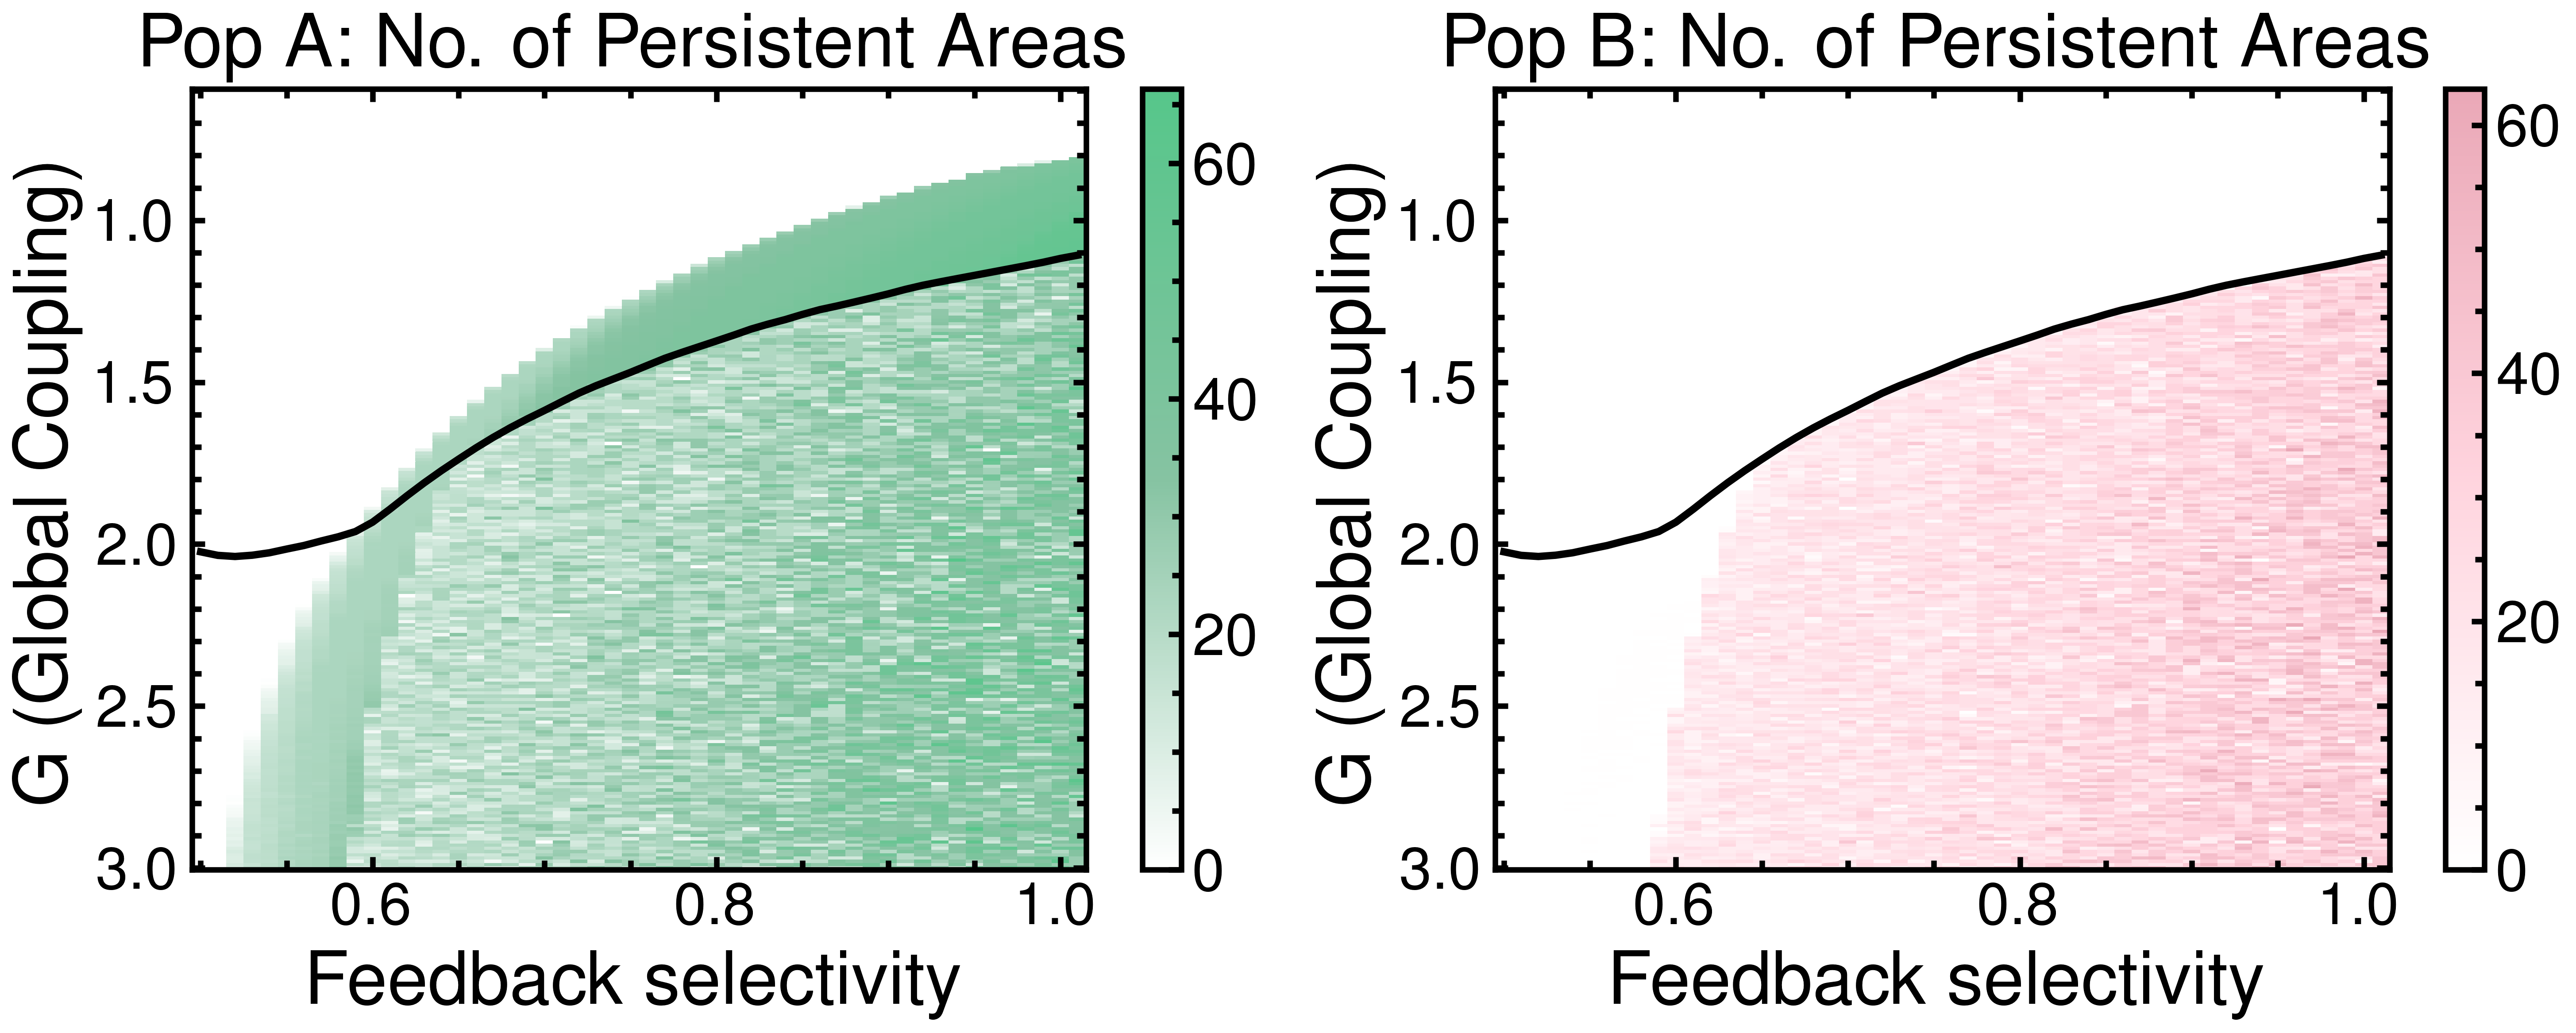

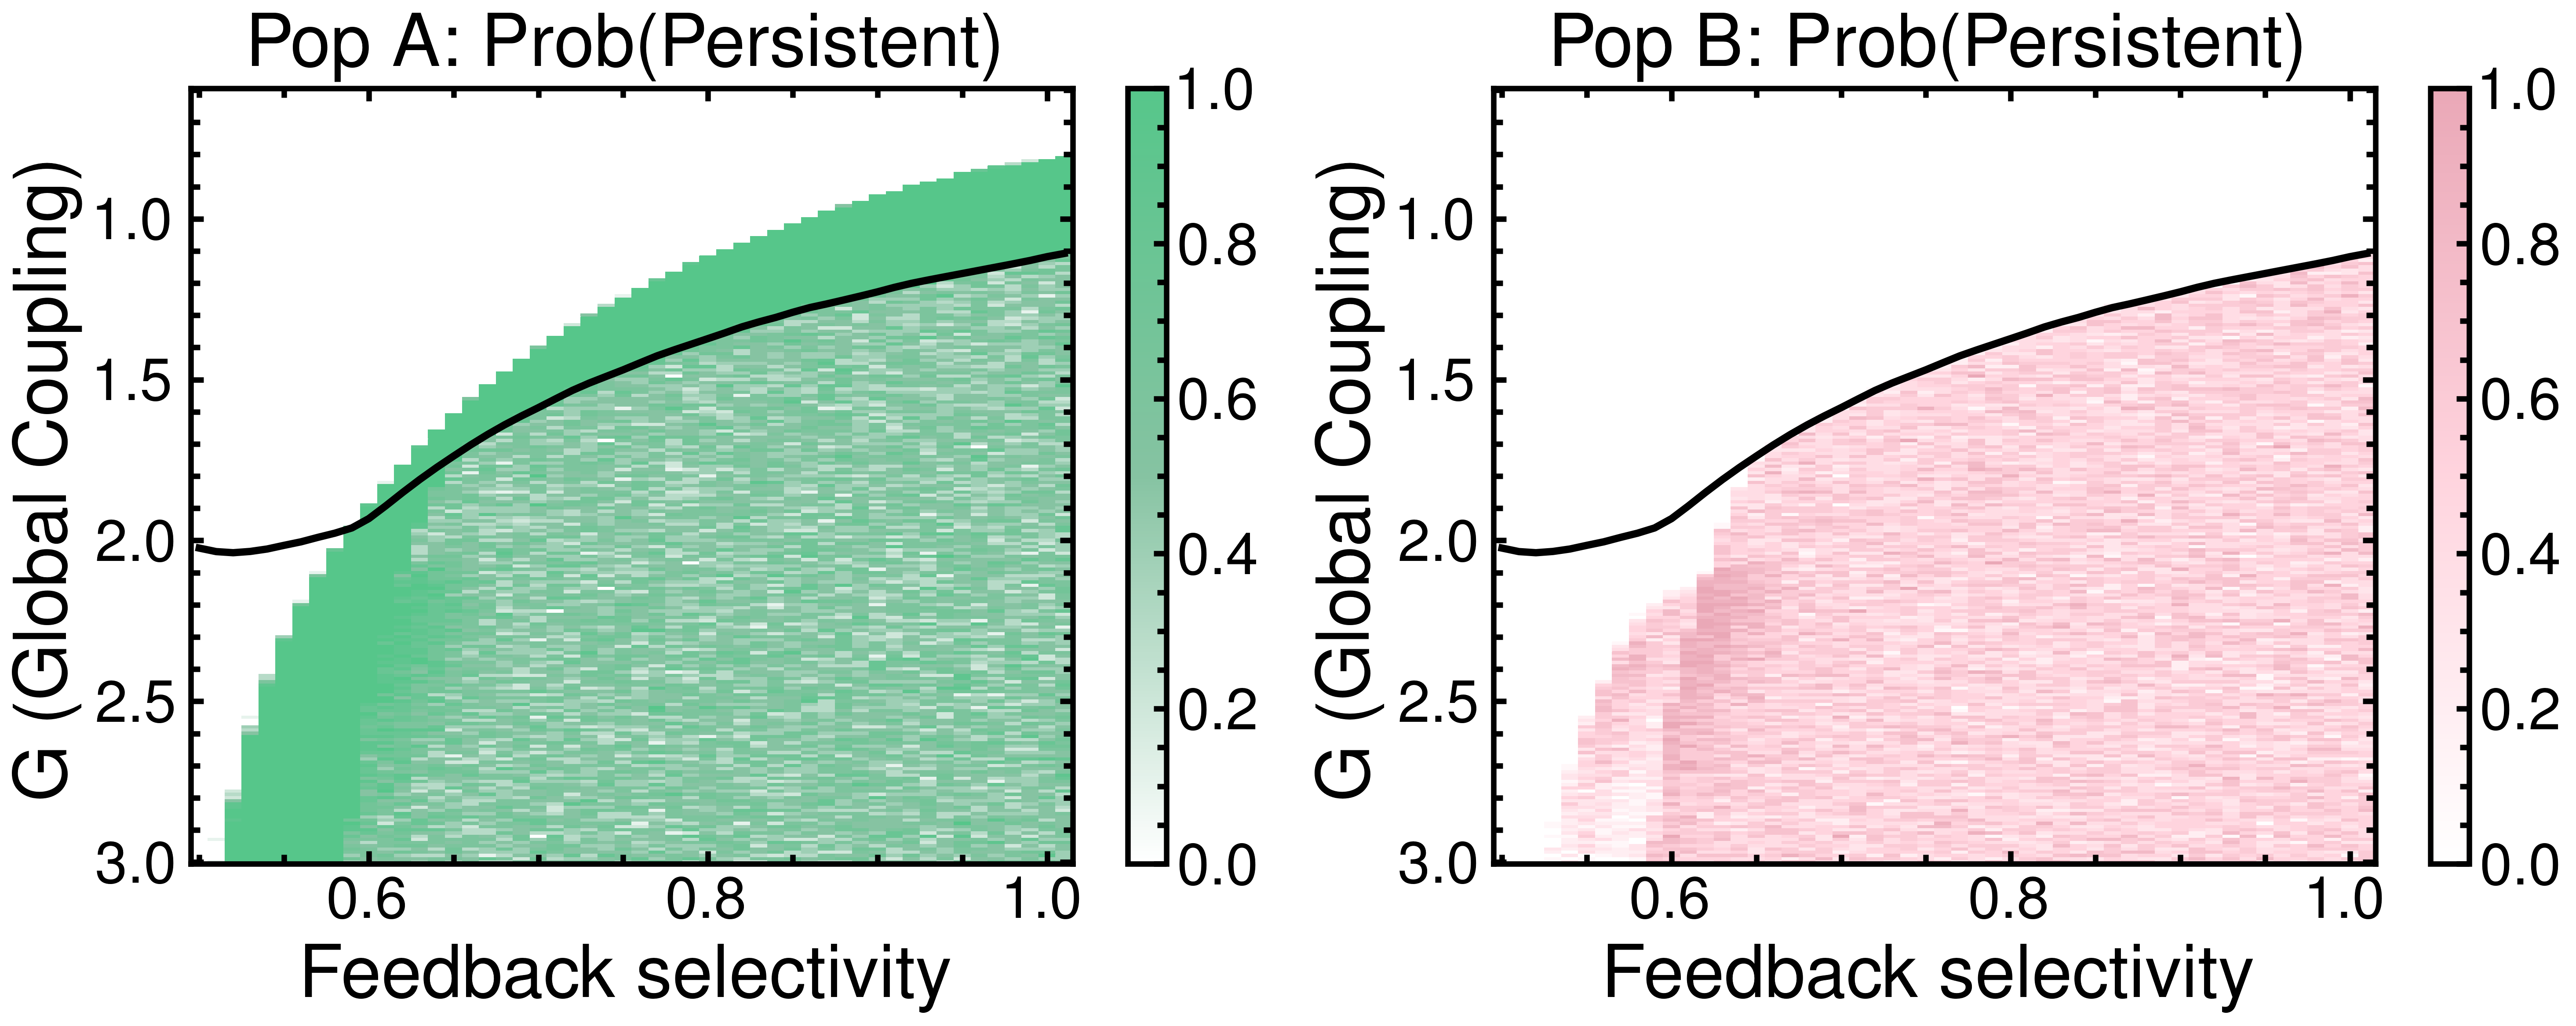

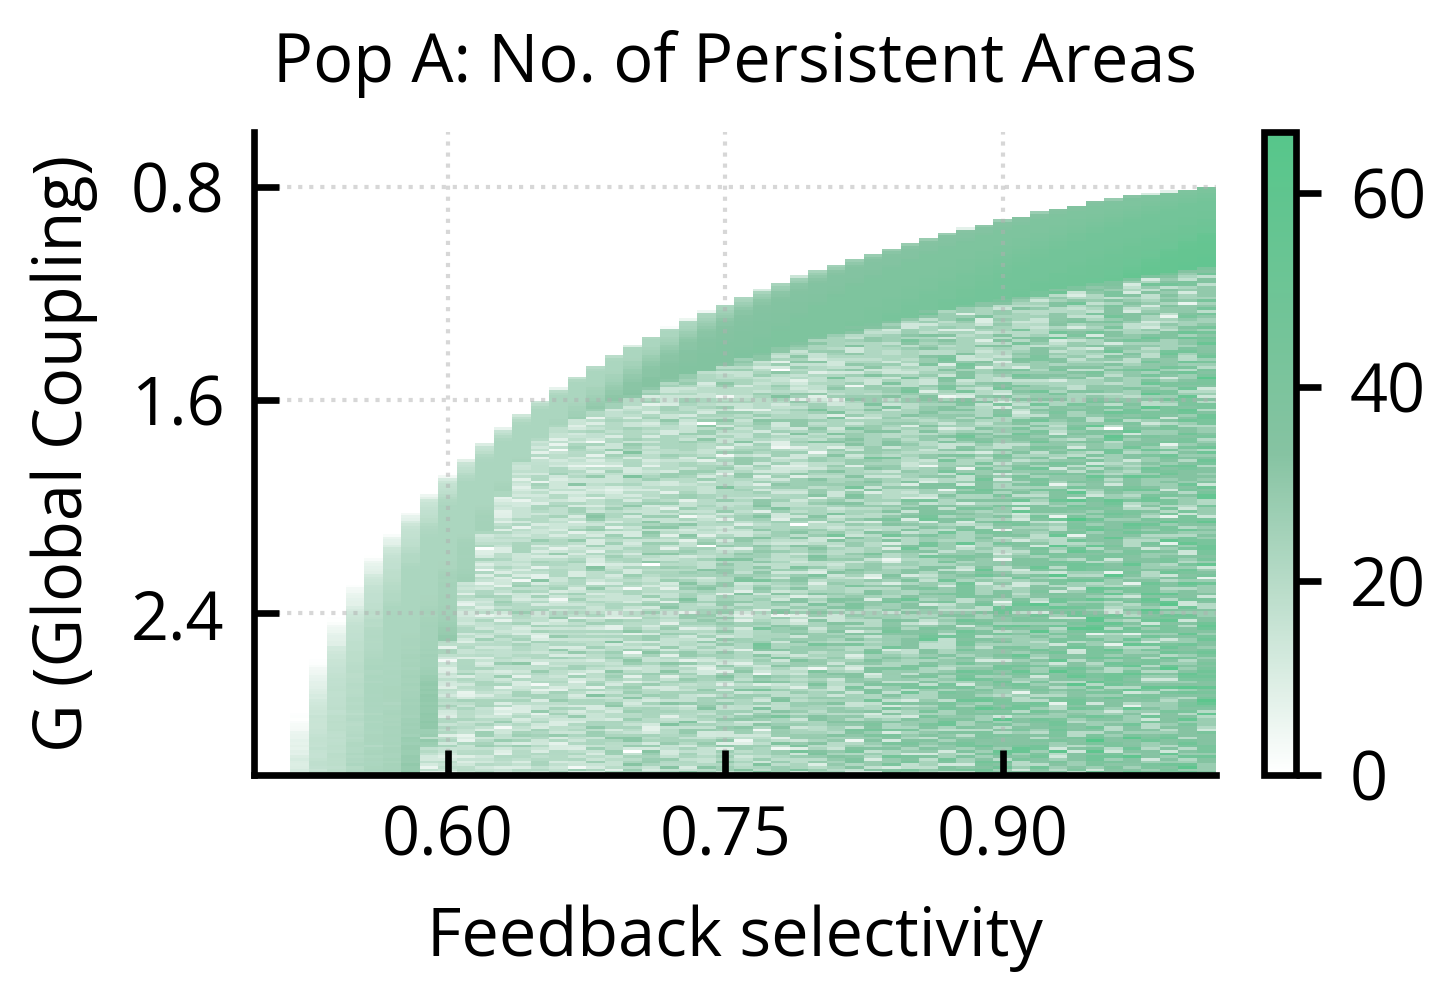

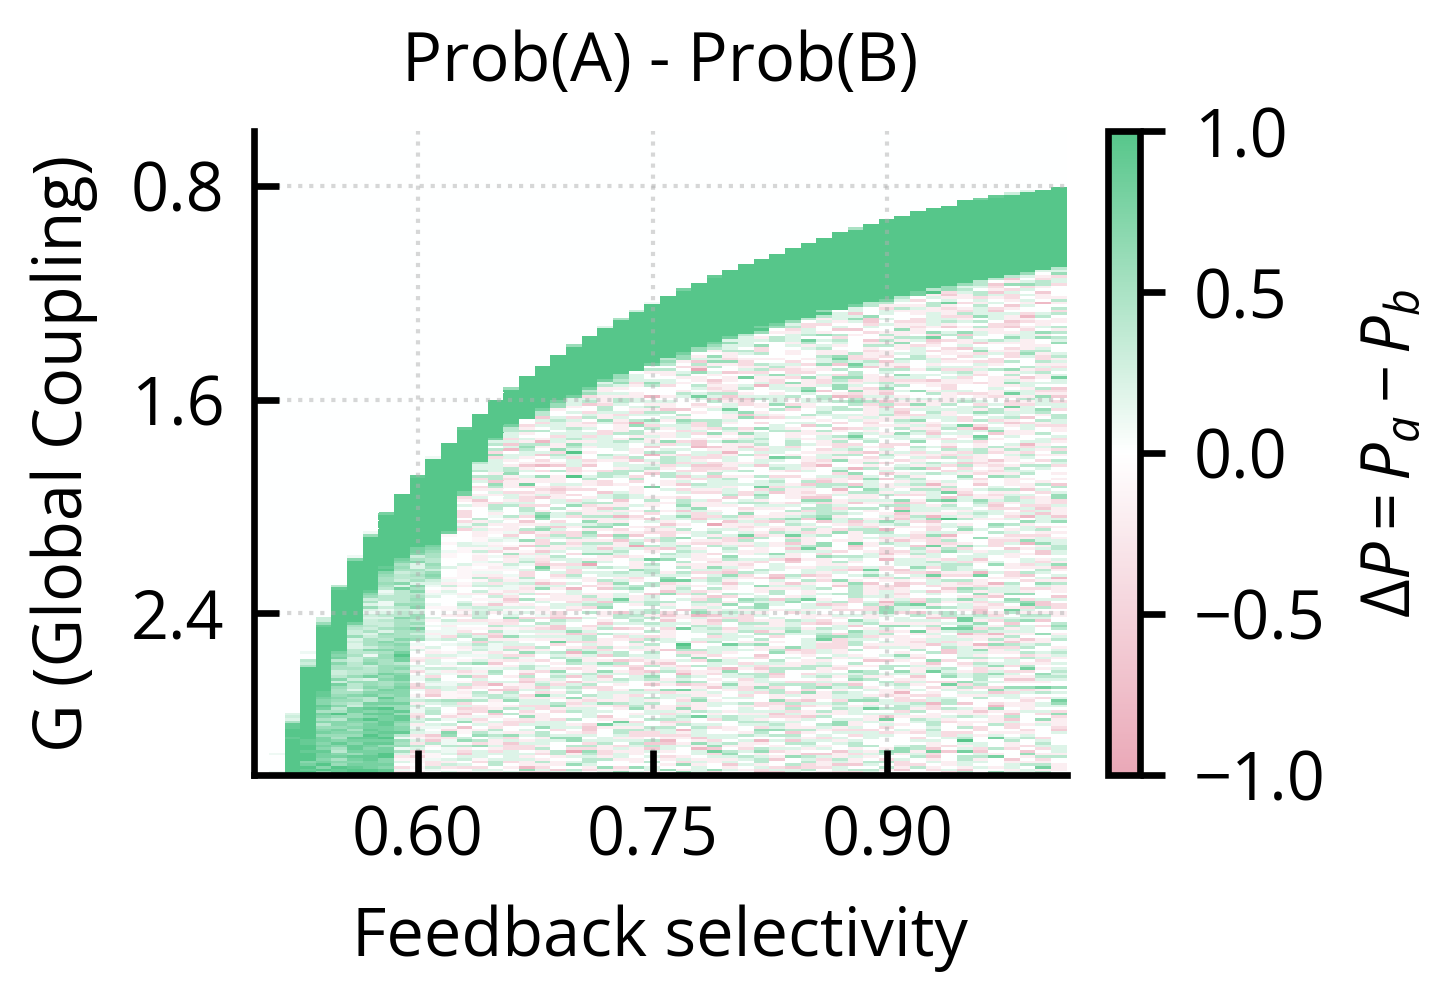

All plots generated and saved in: ../results/G_selectivity_param_sweep
Saved region table to: ../results/G_selectivity_param_sweep/no_spontswitch_region_meanA_up_to40.csv


In [4]:
from scipy.ndimage import gaussian_filter1d
from matplotlib.ticker import MaxNLocator
def style_ax(ax, nbins=4):
        ax.minorticks_off()
        ax.xaxis.set_major_locator(MaxNLocator(nbins))
        ax.yaxis.set_major_locator(MaxNLocator(nbins))
        ax.grid(which='major', linestyle=':', alpha=0.5)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
        ax.xaxis.set_ticks_position('bottom')
        ax.yaxis.set_ticks_position('left')
        ax.tick_params(top=False, right=False)

def style_cbar(cbar, nbins=4):
    cbar.locator = MaxNLocator(nbins)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=3, width=0.8)

def plot_forbidden_gap_analysis():
    csv_path = '../results/G_selectivity_param_sweep/persistent_activity_stats_all_runs.csv'
    results_dir = '../results/G_selectivity_param_sweep'
    df = pd.read_csv(csv_path, delimiter=",", skipinitialspace=True)
    df = df[df['G'] <= 3] # Simulation didn't work for some values above this

    col_g = "G"
    col_selectivity = "selectivity"
    col_no_persist = "Prob_NoPersist"
    col_a_only = "Prob_A_Only"
    col_b_only = "Prob_B_Only"
    col_a_b = "Prob_A_B"
    col_mean_a = "MeanAreasA_uncond"
    col_mean_b = "MeanAreasB_uncond"
    col_spont_switch = "Prob_SpontSwitch"

    # Create pivot tables for the original columns
    piv_no_persist = df.pivot(index=col_g, columns=col_selectivity, values=col_no_persist)
    piv_a_only = df.pivot(index=col_g, columns=col_selectivity, values=col_a_only)
    piv_b_only = df.pivot(index=col_g, columns=col_selectivity, values=col_b_only)
    piv_a_b = df.pivot(index=col_g, columns=col_selectivity, values=col_a_b)

    # Pivot of spontaneous switch probability
    piv_spont = df.pivot(index=col_g, columns=col_selectivity, values=col_spont_switch)
    
    # Parameters
    spont_thresh = 0.01

    sel_vals = piv_spont.columns.values
    g_vals = piv_spont.index.values

    boundary_g = []

    for s in sel_vals:
        col = piv_spont[s].values # Prob_SpontSwitch at fixed selectivity, varying G
        idx = np.where(col > spont_thresh)[0]
        if len(idx) == 0:
            boundary_g.append(np.nan) # no spont switching at this selectivity
        else:
            boundary_g.append(g_vals[idx[0]]) # lowest G with spont switching

    boundary_g = np.array(boundary_g)

    boundary_g_smooth = gaussian_filter1d(boundary_g, sigma=1.0)

    # Mean Number of Areas for A and B
    piv_mean_a = df.pivot(index=col_g, columns=col_selectivity, values=col_mean_a)
    piv_mean_b = df.pivot(index=col_g, columns=col_selectivity, values=col_mean_b)

    plt.figure(figsize=(10, 4))

    # Mean Areas A
    plt.subplot(1, 2, 1)
    plt.title("Pop A: No. of Persistent Areas")
    imA = plt.pcolor(
        piv_mean_a.columns,
        piv_mean_a.index,
        piv_mean_a.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    plt.plot(
        sel_vals,
        boundary_g_smooth,
        color='k',
        linewidth=2,
        label="Spontaneous switching"
    )
    plt.gca().invert_yaxis()
    plt.xlabel("Feedback selectivity")
    plt.ylabel("G (Global Coupling)")
    plt.colorbar(imA)

    # Mean Areas B
    plt.subplot(1, 2, 2)
    plt.title("Pop B: No. of Persistent Areas")
    imB = plt.pcolor(
        piv_mean_b.columns,
        piv_mean_b.index,
        piv_mean_b.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    plt.plot(
        sel_vals,
        boundary_g_smooth,
        color='k',
        linewidth=2,
        label="Spontaneous switching"
    )
    plt.gca().invert_yaxis()
    plt.xlabel("Feedback selectivity")
    plt.ylabel("G (Global Coupling)")
    plt.colorbar(imB)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "mean_areas_AB.png"), dpi=1200)
    plt.show()

    # Probability(A) & Probability(B), plus difference
    # Probability(A) = Probability(A Only) + Probability(A & B)
    # Probability(B) = Probability(B Only) + Probability(A & B)

    df["Probability(A)"] = df[col_a_only] + df[col_a_b]
    df["Probability(B)"] = df[col_b_only] + df[col_a_b]
    df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]

    piv_probA = df.pivot(index=col_g, columns=col_selectivity, values="Probability(A)")
    piv_probB = df.pivot(index=col_g, columns=col_selectivity, values="Probability(B)")
    piv_probDiff = df.pivot(index=col_g, columns=col_selectivity, values="ProbDiff(A-B)")

    # Plot Probability(A) and Probability(B) side by side
    plt.figure(figsize=(10, 4))
    # Probability(A)
    plt.subplot(1, 2, 1)
    plt.title("Pop A: Prob(Persistent)")
    imA = plt.pcolor(
        piv_probA.columns,
        piv_probA.index,
        piv_probA.values,
        cmap=cmaps_phase['pop_A'],
        shading='auto'
    )
    plt.plot(
        sel_vals,
        boundary_g_smooth,
        color='k',
        linewidth=2,
        label="Spontaneous switching"
    )
    plt.gca().invert_yaxis()
    plt.xlabel("Feedback selectivity")
    plt.ylabel("G (Global Coupling)")
    plt.colorbar(imA)

    # Probability(B)
    plt.subplot(1, 2, 2)
    plt.title("Pop B: Prob(Persistent)")
    imB = plt.pcolor(
        piv_probB.columns,
        piv_probB.index,
        piv_probB.values,
        cmap=cmaps_phase['pop_B'],
        shading='auto'
    )
    plt.plot(
        sel_vals,
        boundary_g_smooth,
        color='k',
        linewidth=2,
        label="Spontaneous switching"
    )
    plt.gca().invert_yaxis()
    plt.xlabel("Feedback selectivity")
    plt.ylabel("G (Global Coupling)")
    plt.colorbar(imB)

    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, "prob_A_vs_prob_B.png"), dpi=1200)
    plt.show()
    
    # FOR FIGURE in PAPER
    # Same style as the other combined/standalone panels in the project: Open Sans,
    # 8 pt, usetex off (the 'science' style would otherwise switch text to LaTeX,
    # which ignores font.family), fonttype 42 so text stays editable in the pdf.
    # mathtext entries keep the $\Delta P$ label in Open Sans too.
    import matplotlib as mpl
    fig_params = {
        "text.usetex": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Open Sans"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Open Sans",
        "mathtext.it": "Open Sans:italic",
        "mathtext.bf": "Open Sans:bold",
        "mathtext.cal": "Open Sans:italic",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.title_fontsize": 8,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "pdf.fonttype": 42,   # keep text as editable text, not outlines
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }

    # figsize is in inches, so divide the cm by 2.54
    CM = 2.54
    PANEL_W = (18.4 / 3) / CM   # a third of the page width, minus a margin
    PANEL_H = 4.2 / CM

    # Mean number of areas A
    with mpl.rc_context(fig_params):
        # constrained_layout fits the colorbar without changing the figure size
        fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H), constrained_layout=True)
        ax.set_title("Pop A: No. of Persistent Areas")

        imA = ax.pcolor(
            piv_mean_a.columns,
            piv_mean_a.index,
            piv_mean_a.values,
            cmap=cmaps_phase['pop_A'],
            shading='auto'
        )
        ax.invert_yaxis()
        ax.set_xlabel("Feedback selectivity")
        ax.set_ylabel("G (Global Coupling)")

        # ax.plot(
        #     sel_vals,
        #     boundary_g_smooth,
        #     color='k',
        #     linewidth=2,
        #     label="Spontaneous switching"
        # )
        style_ax(ax, nbins=4)
        cbar = fig.colorbar(imA, ax=ax)
        style_cbar(cbar, nbins=4)
        # no bbox_inches='tight', so the file keeps the exact panel size
        fig.savefig(os.path.join(results_dir, "prob_pop_A.pdf"))
        plt.show()

    # Plot Probability(A)-Probability(B)
    with mpl.rc_context(fig_params):
        fig, ax = plt.subplots(figsize=(PANEL_W, PANEL_H), constrained_layout=True)
        ax.set_title("Prob(A) - Prob(B)")

        imDiff = ax.pcolor(
            piv_probDiff.columns,
            piv_probDiff.index,
            piv_probDiff.values,
            cmap=cmaps_phase['pop_A_minus_B'],
            shading='auto'
        )
        ax.invert_yaxis()
        ax.set_xlabel("Feedback selectivity")
        ax.set_ylabel("G (Global Coupling)")

        # ax.plot(
        #     sel_vals,
        #     boundary_g_smooth,
        #     color='k',
        #     linewidth=2,
        #     label="Spontaneous switching"
        # )

        style_ax(ax, nbins=4)
        cbar = fig.colorbar(imDiff, ax=ax)
        style_cbar(cbar, nbins=4)
        cbar.set_label(r'$\Delta P = P_a - P_b$')
        fig.savefig(os.path.join(results_dir, "prob_diff_A_minus_B.pdf"))
        plt.show()

    print("All plots generated and saved in:", results_dir)
    
    spont_thresh = 0.01
    target_mean = 40.0
    tol = 1e-6

    selected_rows = []

    # Loop over selectivity values in order
    for s in np.sort(df[col_selectivity].unique()):
        # choose only parameter points with no spontaneous switching
        df_sel = df[(df[col_selectivity] == s) &
                    (df[col_spont_switch] <= spont_thresh)]

        if df_sel.empty:
            continue # nothing in the no-switch region at this selectivity

        # priority 1: mean exactly 40
        cand = df_sel[np.isclose(df_sel[col_mean_a], target_mean, atol=tol)]

        if cand.empty:
            # priority 2: mean in [30, 40] and as large as possible
            cand = df_sel[(df_sel[col_mean_a] >= 30.0) &
                          (df_sel[col_mean_a] <= 40.0)]
            if not cand.empty:
                cand = cand.sort_values(col_mean_a, ascending=False).iloc[[0]]
            else:
                # priority 3: mean in [0, 40] and as large as possible
                cand = df_sel[(df_sel[col_mean_a] >= 0.0) &
                              (df_sel[col_mean_a] <= 40.0)]
                if cand.empty:
                    # nothing usable at this selectivity
                    continue
                cand = cand.sort_values(col_mean_a, ascending=False).iloc[[0]]
        else:
            # if you have 40; just pick one, e.g. smallest G
            cand = cand.sort_values(col_g, ascending=True).iloc[[0]]

        row = cand.iloc[0]
        selected_rows.append({
            col_selectivity: row[col_selectivity],
            col_g:           row[col_g],
            col_mean_a:      row[col_mean_a]
        })

    region_df = pd.DataFrame(selected_rows)
    out_path = os.path.join(results_dir, "no_spontswitch_region_meanA_up_to40.csv")
    region_df.to_csv(out_path, index=False)
    print("Saved region table to:", out_path)

if __name__ == "__main__":
    plot_forbidden_gap_analysis()
